In [5]:
%load_ext autoreload
%autoreload 2

import numpy as np 
import functions 

from matplotlib import pyplot as plt


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [156]:
sigma = np.load("data/peyta_sigma.npy")
dsigma = np.load("data/peyta_dsigma.npy")
theta_cm = np.load("data/peyta_theta_cm.npy")
ke_cm = np.load("data/peyta_ke_cm.npy")

rounded_theta_cm = np.ceil( theta_cm / 5) * 5

print( np.unique( rounded_theta_cm ) )

[ 55.  60.  70.  75.  80.  90.  95. 105. 110. 120. 130. 135. 140. 145.
 160. 165.]


In [43]:
all_cs = functions.get_all_cs(rounded_theta_cm, ke_cm, sigma, dsigma)

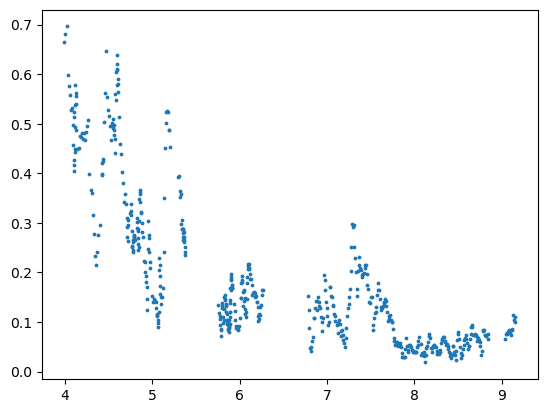

In [61]:
plt.scatter(all_cs["55.0"]["ke"], all_cs["55.0"]["sigma"], s=3)
plt.show()

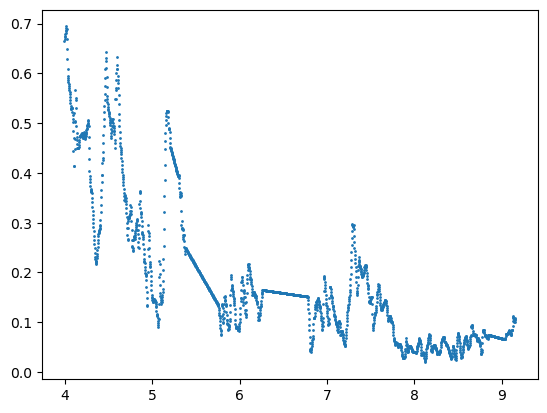

In [ ]:
# This is bad, it's interpolating the gaps too. 
# Only want to apply interpolation to the valid regions.

ke_55 = all_cs["55.0"]["ke"]
sigma_55 = all_cs["55.0"]["sigma"]

ke_55_uniform = np.linspace(
    ke_55.min(),
    ke_55.max(),
    2000
)

sigma_55_uniform = np.interp(
    ke_55_uniform, 
    ke_55,
    sigma_55
)


plt.scatter(ke_55_uniform, sigma_55_uniform, s=1)

In [103]:
print(np.max(np.diff(ke_55)))
print(np.min(np.diff(ke_55)))
print(np.unique(np.diff(np.round(ke_55, 3))))

0.5114296219762764
0.0
[0.    0.001 0.001 0.002 0.002 0.003 0.003 0.004 0.004 0.005 0.005 0.007
 0.008 0.008 0.008 0.009 0.009 0.009 0.01  0.011 0.012 0.012 0.013 0.013
 0.013 0.014 0.016 0.017 0.017 0.021 0.023 0.024 0.028 0.091 0.191 0.384
 0.511]


In [154]:
interp_55, ke_s, sigma_s = functions.get_interpolation(ke_55, sigma_55, gap_size = 0.1)

197


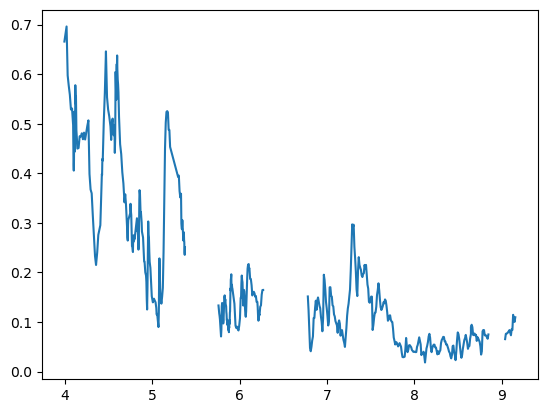

In [155]:
plt.plot(ke_s, sigma_s)